Fig3_E_d2_barrage_rate

✅ Used 10 files; skipped 0.
tile
1    7640
2    7164
3    7224
4    7198
5    7103
6    7227
Name: count_by_tile, dtype: int64

📊 Linear trend on cross-file means:
  R² = 0.939, p = 0.001442, R= -0.969
  files per tile: {1: 10, 2: 10, 3: 10, 4: 10, 5: 10, 6: 10}
Figure saved to D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main\fig3_E_barrage_rate_by_d2_tile_pooled.svg


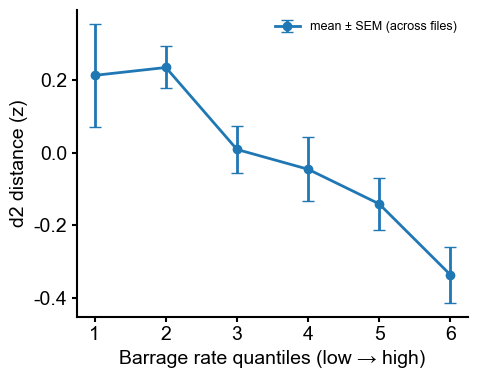

In [1]:
import os, pickle
import numpy as np
import pandas as pd
from scipy.stats import sem
import os
import glob
import pickle
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import sem as scipy_sem # Use a named import to avoid confusion
from scipy.stats import linregress

import numpy as np
from scipy.stats import gaussian_kde
import matplotlib as mpl

import matplotlib as mpl

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
def _force_sextiles(series, k=6):
    """
    Return Int64 tiles 1..k. Try qcut; if it yields <k bins, fall back to
    rank-based qcut that still returns k bins when N>=k. If N<k -> all NA.
    """
    s = pd.to_numeric(series, errors="coerce")
    s = s.replace([np.inf, -np.inf], np.nan)

    # 1) Try ordinary quantile sextiles
    try:
        t = pd.qcut(s, q=k, labels=False, duplicates="drop")
        if pd.Series(t).nunique(dropna=True) == k:
            return t.astype("Int64") + 1
    except Exception:
        pass

    # 2) Fallback: rank-based sextiles (equal-count by rank)
    rk = s.rank(method="first")
    if rk.notna().sum() >= k:
        t = pd.qcut(rk, q=k, labels=False)
        return t.astype("Int64") + 1

    # 3) Not enough rows to form k bins
    return pd.Series(pd.NA, index=s.index, dtype="Int64")

def load_pool_rate_binned(pkl_dir, rate_col, state="NREM", n_bins=6, min_bins_required=2):
    pooled = []
    n_files_used = 0
    n_files_skipped = 0

    for file in os.listdir(pkl_dir):
        if not file.endswith(".pkl"):
            continue
        full_path = os.path.join(pkl_dir, file)
        try:
            with open(full_path, "rb") as f:
                data = pickle.load(f)

            df = data.get("ca1_complete_df", None)
            if df is None or len(df) == 0:
                n_files_skipped += 1; continue

            df = df[df["state"] == state].copy()
            need = ["d2", rate_col]
            if df.empty or not set(need).issubset(df.columns):
                n_files_skipped += 1; continue

            df = df[need].replace([np.inf, -np.inf], np.nan).dropna()
            if df.empty:
                n_files_skipped += 1; continue

            # per-file z of d2
            d2_std = df["d2"].std(ddof=0)
            if not np.isfinite(d2_std) or d2_std == 0:
                n_files_skipped += 1; continue
            df["d2_norm"] = (df["d2"] - df["d2"].mean()) / d2_std

            # ---- FORCE 6 TILES (fallback to rank if qcut collapses) ----
            tiles = _force_sextiles(df[rate_col], k=n_bins)
            df["tile"] = tiles
            n_uniq = df["tile"].nunique(dropna=True)
            if n_uniq < min_bins_required:
                # not enough valid bins (e.g., <6 rows); skip file
                n_files_skipped += 1; continue

            df["file_id"] = os.path.splitext(file)[0]
            df["state"] = state
            df["rate_col"] = rate_col

            pooled.append(df[["file_id","state","rate_col","d2_norm",rate_col,"tile"]])
            n_files_used += 1

        except Exception:
            n_files_skipped += 1
            continue

    if not pooled:
        raise ValueError("No usable data loaded after per-file binning.")

    pooled_df = pd.concat(pooled, ignore_index=True)
    print(f"✅ Used {n_files_used} files; skipped {n_files_skipped}.")
    print(pooled_df.groupby("tile")["d2_norm"].count().rename("count_by_tile"))
    return pooled_df

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

pkl_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\mice_d2_barr_ripple"

# Barrage: per-file quantile binning, then pool
df_barrage_pooled = load_pool_rate_binned(
    pkl_dir, rate_col="barrage_rate_hz", state="NREM", n_bins=6
)

def plot_d2_by_rate_tile_pooled_crossfileSEM(pooled_df, n_bins=6, title=None, color="tab:blue", save_path=None):
    """
    Plot mean z(D²) per tile with SEM computed ACROSS FILES.
    Steps:
      1) per-file, per-tile mean of d2_norm
      2) across-file mean and SEM of those per-file means
    """
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from scipy.stats import linregress

    # keep only 1..n_bins
    d = pooled_df.copy()
    d = d[d["tile"].between(1, n_bins)]

    # --- (1) per-file mean within each tile
    pf = (d.groupby(["file_id","tile"], observed=True)["d2_norm"]
            .mean()
            .rename("pf_mean")
            .reset_index())

    # --- (2) across-file mean & SEM per tile
    tile_mean = pf.groupby("tile")["pf_mean"].mean()
    tile_sem  = pf.groupby("tile")["pf_mean"].apply(lambda x: x.std(ddof=1) / np.sqrt(x.count()))
    n_files_per_tile = pf.groupby("tile")["file_id"].nunique()

    # an entry for every bin 1..n_bins
    idx = pd.Index(range(1, n_bins+1), name="tile")
    tile_mean = tile_mean.reindex(idx)
    tile_sem  = tile_sem.reindex(idx)
    n_files_per_tile = n_files_per_tile.reindex(idx).fillna(0).astype(int)

    xs = tile_mean.index.to_numpy(int)
    ys = tile_mean.values
    es = tile_sem.values

    # linear trend on cross-file means
    ok = np.isfinite(ys)
    if ok.sum() >= 2:
        lr = linregress(xs[ok], ys[ok])
        r2 = lr.rvalue**2
        p  = lr.pvalue
        p_str = ("p < 1e-45" if p < 1e-45 else
         (f"p = {p:.6e}" if p < 0.001 else f"p = {p:.6f}"))
    else:
        r2, p_str = np.nan, "p = NA"

    print("\n📊 Linear trend on cross-file means:")
    print(f"  R² = {r2:.3f}, {p_str}, R= {lr.rvalue:.3f}")
    print("  files per tile:", dict(zip(xs, n_files_per_tile.tolist())))

    # plot
    plt.figure(figsize=(5,4))
    plt.errorbar(xs, ys, yerr=es, fmt='-o', capsize=4, color=color, linewidth=2, label="mean ± SEM (across files)")

    # # optional OLS line for reference
    # if ok.sum() >= 2:
    #     yfit = lr.intercept + lr.slope * xs
    #     plt.plot(xs, yfit, linestyle="--", linewidth=1.5, color=color, alpha=0.6, label="OLS on cross-file means")

    plt.xticks(xs)
    plt.xlabel(title or "Rate tiles (low → high)")
    plt.ylabel("d2 distance (z)")
    try:
        import seaborn as sns
        sns.despine()
    except Exception:
        pass
    ax = plt.gca()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.legend(frameon=False, fontsize=9)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300)
        print(f"Figure saved to {save_path}")
    plt.show()

plot_d2_by_rate_tile_pooled_crossfileSEM(
    df_barrage_pooled, n_bins=6,
    title="Barrage rate quantiles (low → high)",
    color="tab:blue",
    save_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main\fig3_E_barrage_rate_by_d2_tile_pooled.svg"

)

Fig3 F branching ratio

Unique file counts per condition:
condition
Barrage            11
Barrage_Shuffle    11
Name: file, dtype: int64


C:\Users\Cornell\AppData\Local\Temp\ipykernel_28084\1672399378.py:149: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


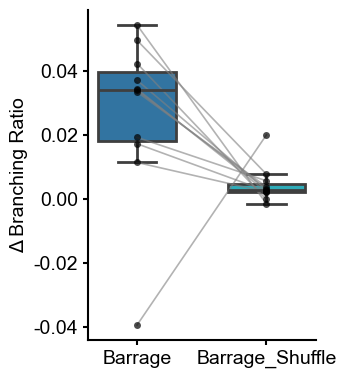

In [1]:
import os
import pickle
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Make mathtext look like Arial
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Arial'
mpl.rcParams['mathtext.it'] = 'Arial:italic'
mpl.rcParams['mathtext.bf'] = 'Arial:bold' 

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# --- Step 1: Load all files ---
base_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\branching_ratio\barr"
files = [f for f in os.listdir(base_dir) if f.endswith("_br_changes.pkl")]

all_rows = []

# --- Step 2: Extract results ---
import numpy as np

all_rows = []

for fname in files:
    fpath = os.path.join(base_dir, fname)
    with open(fpath, "rb") as f:
        payload = pickle.load(f)

    results = payload["results"] if isinstance(payload, dict) and "results" in payload else payload

    parts = fname.split("_")
    animal = parts[0]
    day = parts[1]

    # Collect all values first (for normalization)
    file_values = []
    for key in [
                "barrage_br_changes", "barrage_br_changes_shuffle"]:
        if key in results:
            file_values.extend(results[key])

    file_values = np.array(file_values, dtype=float)
    mean_val = np.nanmean(file_values)
    std_val  = np.nanstd(file_values)

    # Avoid div by zero
    if std_val == 0:
        std_val = 1.0

    # Now add normalized rows
    for key, label in [
        ("barrage_br_changes", "Barrage"),
        ("barrage_br_changes_shuffle", "Barrage_Shuffle"),
    ]:
        if key in results:
            vals = results[key]
            for v in vals:
                v_norm = v # z-score normalization
                all_rows.append({
                    "animal": animal,
                    "day": day,
                    "condition": label,
                    "value": v_norm
                })

# --- Step 3: Build dataframe ---
df = pd.DataFrame(all_rows)
# --- Step 1: Load all files ---
df["file"] = df["animal"].astype(str) + "_" + df["day"].astype(str)

# --- Compute per-file mean per condition ---
pf = (
    df.groupby(["file", "condition"], observed=True)["value"]
      .mean()
      .rename("file_mean")
      .reset_index()
)

print("Unique file counts per condition:")
print(pf.groupby("condition")["file"].nunique())
df["file"] = df["animal"].astype(str) + "_" + df["day"].astype(str)

pf = (
    df.groupby(["file", "condition"], observed=True)["value"]
      .mean()
      .rename("file_mean")
      .reset_index()
)

def draw_paired_lines(ax, df_pair, order, color="gray", alpha=0.5):
    """
    df_pair must contain columns: file, condition, file_mean
    """
    # Pivot to file → [cond1, cond2]
    pivot = df_pair.pivot_table(index="file", columns="condition", values="file_mean", observed=True)

    # Keep only files that have both conditions
    pivot = pivot.dropna()

    # Draw connecting lines
    for file_id, row in pivot.iterrows():
        ax.plot(
            [order[0], order[1]],
            [row[order[0]], row[order[1]]],
            color=color, alpha=alpha, linewidth=1.2
        )

# Barrage subset
pf_barrage= pf[pf["condition"].isin(["Barrage", "Barrage_Shuffle"])].copy()
pal_barrage = {"Barrage": "tab:blue", "Barrage_Shuffle": "tab:cyan"}
order_barrage = ["Barrage", "Barrage_Shuffle"]
# --- Paired lines FIRST (so boxplot/stripplot draw over them) ---

plt.figure(figsize=(3.5,4))
ax = plt.gca()

# --- Paired lines ---
# --- Boxplot ---
sns.boxplot(
    data=pf_barrage, x="condition", y="file_mean",
    order=order_barrage, palette=pal_barrage,
    showfliers=False, width=0.6, linewidth=2, ax=ax
)

# --- Points ---
sns.stripplot(
    data=pf_barrage, x="condition", y="file_mean",jitter=False,
    order=order_barrage, color="k", alpha=0.7
    , size=5, ax=ax
)

ax.set_xlabel("")
ax.set_ylabel(r"Δ Branching Ratio")
sns.despine(top=True, right=True)
plt.tight_layout()
draw_paired_lines(ax, pf_barrage, order_barrage, color="gray", alpha=0.6)
save_path2 = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main\fig3_F_barrage_br_changes_perfile_paired.svg"
plt.savefig(save_path2, dpi=300)
plt.show()

# print(f"Saved Barrage plot with paired lines: {save_path2}")

In [9]:
import statsmodels.formula.api as smf


df["animal"] = df["animal"].astype("category")
df["day"]    = df["day"].astype("category")
df["animal_day"] = df["animal"].astype(str) + "_" + df["day"].astype(str)

df = df.dropna(subset=["value", "condition", "animal", "day", "animal_day"]).reset_index(drop=True)
df["condition"] = df["condition"].astype("category")

# Fixed: condition + animal
# Random intercept: animal_day (session)
model = smf.mixedlm("value ~ C(condition) + C(animal)", data=df, groups=df["animal_day"], re_formula="1")
res = model.fit(method="lbfgs")
import numpy as np
from scipy.stats import norm

fe = res.fe_params
cov_fe = res.cov_params().loc[fe.index, fe.index]

def contrast_test(coeffs: dict, label: str):
    """
    Calculates exact p-values for LMM contrasts using log-space
    to avoid underflow for high z-scores.
    """
    # 1. Map coefficients to weight vector
    c = np.zeros(len(fe))
    for i, name in enumerate(fe.index):
        if name in coeffs:
            c[i] = coeffs[name]
    
    # 2. Calculate Difference, SE, and Z
    diff = float(c @ fe.values)
    se   = float(np.sqrt(c @ cov_fe.values @ c))
    z    = abs(diff / se)
    
    # 3. EXACT P-VALUE CALCULATION
    # norm.logsf(z) returns ln(P_one_sided). 
    # For two-sided: ln(2 * P_one_sided) = ln(2) + ln(P_one_sided)
    ln_p = np.log(2.0) + norm.logsf(z)
    
    # Convert to log10 to find the exponent
    log10_p = ln_p / np.log(10.0)
    exponent = int(np.floor(log10_p))
    significand = 10**(log10_p - exponent)
    
    # Format the string based on magnitude
    if exponent < -4:
        p_str = f"{significand:.3f}e{exponent}"
    else:
        p_str = f"{np.exp(ln_p):.5f}"

    print(f"{label}:")
    print(f"  diff = {diff:.4f}")
    print(f"  z    = {z:.2f}")
    print(f"  p    = {p_str}")
    
    return diff, np.exp(ln_p) if ln_p > -700 else 0.0

# Barrage vs Barrage_Shuffle = coeff[Barrage_Shuffle]
contrast_test({
    "C(condition)[T.Barrage_Shuffle]": -1
}, "Barrage vs Barrage_Shuffle")

Barrage vs Barrage_Shuffle:
  diff = 0.0239
  z    = 5.14
  p    = 2.714e-7


c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2245: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values

(0.023883485540965893, 2.714316702618124e-07)

Fig3_G_manipulation

N_target = 1000
Dropping files (too few points in at least one epoch): ['SNCG08_day14', 'SNCG08_day16', 'SNCG08_day17', 'SNCG09_day10', 'SNCG09_day12', 'SNCG09_day13']
Target N per file×epoch = 1000


C:\Users\Cornell\AppData\Local\Temp\ipykernel_28084\272018690.py:110: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  chk = (balanced_df.groupby(['animal_day','epoch']).size()
C:\Users\Cornell\AppData\Local\Temp\ipykernel_28084\272018690.py:166: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Cornell\AppData\Local\Temp\ipykernel_28084\272018690.py:178: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Baseline", "Barrage disruption"])


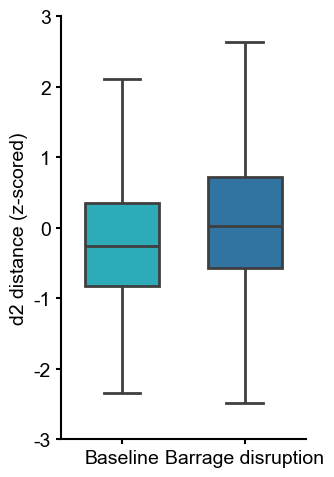

Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main\fig5_F_barrage_manipulation_box_d2_pooled.svg


In [11]:
import os, glob, pickle, re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

SN_DIR = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\manipulation\sncg"
rng = np.random.default_rng(0)
order = ['presleep', 'postsleep']
N_target = 1000  # per-file x epoch sample size

# ---------- load ----------
def load_plot_df(pkl_path):
    with open(pkl_path, "rb") as f:
        obj = pickle.load(f)
    if isinstance(obj, pd.DataFrame):
        df = obj.copy()
    elif isinstance(obj, dict):
        df = obj.get("plot_df")
        if not isinstance(df, pd.DataFrame):
            df = next((v for v in obj.values() if isinstance(v, pd.DataFrame)), None)
            if df is None:
                raise ValueError("no DataFrame found in PKL")
    else:
        raise ValueError("unsupported PKL content")

    stem = os.path.splitext(os.path.basename(pkl_path))[0]
    df["animal_day"] = stem
    m = re.match(r"(?P<animal>.+)_day(?P<day>\d+)$", stem, flags=re.IGNORECASE)
    if m:
        df["animal"] = m.group("animal")
        df["day"] = int(m.group("day"))
    else:
        df["animal"] = stem; df["day"] = pd.NA
    return df

all_pkls = sorted(glob.glob(os.path.join(SN_DIR, "*.pkl")))
pooled_df = pd.concat([load_plot_df(p) for p in all_pkls], ignore_index=True)

# ---------- filter to epochs ----------
plot_df = pooled_df[pooled_df['epoch'].isin(order)].copy()
plot_df['epoch'] = pd.Categorical(plot_df['epoch'], categories=order, ordered=True)

# ---------- counts & choose valid files ----------
counts = (plot_df.groupby(['animal_day','epoch'], observed=True)
                 .size()
                 .unstack('epoch', fill_value=0)
                 .reindex(columns=order, fill_value=0))

valid_files = counts.index[counts.min(axis=1) >= N_target]
dropped = sorted(set(counts.index) - set(valid_files))
print(f"N_target = {N_target}")
print("Dropping files (too few points in at least one epoch):", dropped)

# keep only valid files
plot_df = plot_df[plot_df['animal_day'].isin(valid_files)].copy()

# ---------- (optional) z-score within file ----------
# g = plot_df.groupby('animal_day')['d2']
# mu = g.transform('mean'); sd = g.transform('std').replace(0, np.nan)
# plot_df['d2'] = ((plot_df['d2'] - mu) / sd).fillna(0.0)  # overwrite with z if desired

import numpy as np
import pandas as pd

rng = np.random.default_rng(0)
order = ['presleep', 'postsleep']  # epochs compared

# starting point: `pooled_df` with ['epoch','d2','animal_day', ...]
plot_df = pooled_df[pooled_df['epoch'].isin(order)].copy()
plot_df['epoch'] = pd.Categorical(plot_df['epoch'], categories=order, ordered=True)

# OPTIONAL: z-score within file so scales are comparable
g = plot_df.groupby('animal_day')['d2']
mu = g.transform('mean')
sd = g.transform('std').replace(0, np.nan)
plot_df['d2_z'] = ((plot_df['d2'] - mu) / sd).fillna(0.0)  # comment out to use raw d2

# ---- choose a target N per file×epoch ----
# Option 1: set manually
N_target = 1000

# Option 2 (auto): use median of per-file mins across epochs
# counts = (plot_df.groupby(['animal_day','epoch']).size()
#                    .unstack('epoch', fill_value=0)
#                    .reindex(columns=order, fill_value=0))
# N_target = int(np.median(counts.min(axis=1)))

print(f"Target N per file×epoch = {N_target}")

# ---- resample each file×epoch to N_target (upsample with replacement if needed) ----
rows = []
info = []  # keep a small log
for f, df_f in plot_df.groupby('animal_day', sort=False):
    for ep in order:
        idx_pool = df_f.index[df_f['epoch'] == ep].to_numpy()
        n = idx_pool.size
        if n == 0:
            # no data at all for this file×epoch → fill by bootstrapping from the *other* epoch?
            # safer to skip; or handle explicitly if needed
            continue
        replace = n < N_target                    # upsample if short
        choice = rng.choice(idx_pool, size=N_target, replace=replace)
        rows.append(df_f.loc[choice])
        info.append((f, ep, n, 'upsampled' if replace else 'downsampled'))

balanced_df = pd.concat(rows, ignore_index=True)

# quick check: all groups should be exactly N_target
chk = (balanced_df.groupby(['animal_day','epoch']).size()
                       .unstack('epoch', fill_value=0)
                       .reindex(columns=order, fill_value=0))
assert (chk.min().min() == N_target) and (chk.max().max() == N_target)
import os, glob, pickle, re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5


palette=['tab:cyan', 'tab:blue']  # colors for the two epochs
fig, ax = plt.subplots(figsize=(3.5, 5))

sns.boxplot(
    data=balanced_df,
    x="epoch",
    y="d2_z",
    order=order,
    width=0.6,
    showfliers=False,
    linewidth=2,
    palette=palette,
    ax=ax
)

ax.set_xticklabels(["Baseline", "Barrage disruption"])
ax.set_xlabel("")
ax.set_ylabel("d2 distance (z-scored)")
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.grid(False)

plt.ylim(-3, 3)
plt.tight_layout()

save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main\fig5_F_barrage_manipulation_box_d2_pooled.svg"
plt.savefig(save_path, dpi=300)
plt.show()

print(f"Saved: {save_path}")

In [12]:
# ==== Linear Mixed Model: d2_z ~ epoch + (1 | animal_day) ====
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd
label_map = {'presleep': 'baseline', 'postsleep': 'barrage disruption'}
balanced_df = balanced_df.copy()

balanced_df["animal"] = balanced_df["animal"].astype("category")

balanced_df["epoch_lab"] = balanced_df["epoch"].map(label_map)
balanced_df["epoch_lab"] = pd.Categorical(
    balanced_df["epoch_lab"], categories=["baseline", "barrage disruption"], ordered=True
)

# epoch coding for the model: presleep is reference
balanced_df["epoch"] = pd.Categorical(
    balanced_df["epoch"], categories=["presleep", "postsleep"], ordered=True
)

balanced_df = balanced_df.dropna(subset=["d2", "epoch", "animal", "animal_day"]).reset_index(drop=True)

# animal included as fixed effect
model = smf.mixedlm("d2 ~ C(epoch) + C(animal)", data=balanced_df, groups=balanced_df["animal_day"], re_formula="1")
res = model.fit(method="lbfgs")

term = "C(epoch)[T.postsleep]"
coef = res.params.get(term, np.nan)
pval = res.pvalues.get(term, np.nan)
ci_lo, ci_hi = res.conf_int().loc[term].to_list()

print("\n--- Key result (barrage disruption vs baseline) ---")
print(f"Coef: {coef:.4f}  95% CI: [{ci_lo:.4f}, {ci_hi:.4f}]  p = {pval:.3g}")

# annotate figure (if `ax` still in scope)
try:
    y0, y1 = ax.get_ylim()
    ax.text(0.5, y1 - 0.05*(y1-y0),
            f"LMM: barrage disruption - baseline\np = {pval:.3g}  (coef={coef:.3f})",
            ha="center", va="top", fontsize=10)
    plt.tight_layout(); plt.show()
except Exception:
    pass


--- Key result (barrage disruption vs baseline) ---
Coef: 0.0055  95% CI: [0.0047, 0.0063]  p = 1.91e-39


c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2245: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values

<Figure size 640x480 with 0 Axes>

Fig3H ISI entropy

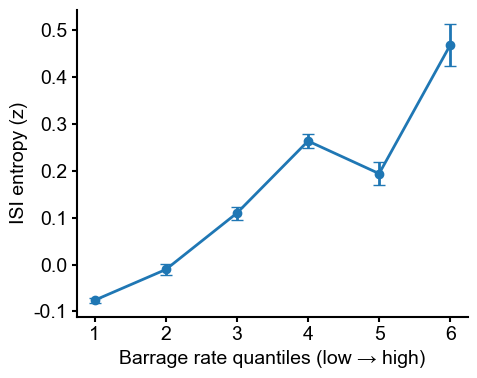

✅ Done. D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main\fig3_H_pooled_ISIentropyZ_vs_barrage_tile.svg

Ripple linear trend

Barrage linear trend
  slope     : 0.0994308
  intercept : -0.190274
  rvalue    : 0.946241
  pvalue    : 0.00425733
  stderr    : 0.0169947
  Pearson r   : 0.9462
  Pearson p   : 0.004257


In [3]:
import os, glob, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib as mpl

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# ==========================
# ---------- I/O ----------
def load_pooled_per_center(save_dir, state_filter="NREM"):
    if not os.path.isdir(save_dir): raise FileNotFoundError(save_dir)
    files = sorted(glob.glob(os.path.join(save_dir, "*.pkl")))
    if not files: raise FileNotFoundError(f"No .pkl in {save_dir}")

    want_num = ["center_s","isi_entropy","n_spikes","ripple_rate","barrage_rate"]
    out = []
    for f in files:
        try:
            obj = pd.read_pickle(f)
        except Exception:
            with open(f, "rb") as fh: obj = pickle.load(fh)

        if isinstance(obj, dict):
            df = obj.get("per_center")
            if not isinstance(df, pd.DataFrame): continue
            animal, day = obj.get("animal_name"), obj.get("day")
        elif isinstance(obj, pd.DataFrame):
            df, animal, day = obj.copy(), None, None
        else:
            continue

        base = os.path.splitext(os.path.basename(f))[0].split("_")
        df["animal_name"] = df.get("animal_name", animal or (base[0] if base else "unknown"))
        df["day"]         = df.get("day",         day    or (base[1] if len(base)>1 else "unknown"))

        if "state" in df.columns and state_filter is not None:
            df = df[df["state"].astype(str).str.lower()==str(state_filter).lower()]
            if df.empty: continue

        for c in want_num:
            if c in df.columns: df[c] = pd.to_numeric(df[c], errors="coerce")

        out.append(df)

    if not out: return pd.DataFrame()
    pooled = pd.concat(out, ignore_index=True)
    sort_cols = [c for c in ["animal_name","day","center_s"] if c in pooled.columns]
    return pooled.sort_values(sort_cols).reset_index(drop=True)

# ---------- per-session z ----------
def add_session_zscores(df, target_cols, session_cols=("animal_name","day"), robust=False, eps=1e-12):
    cols = [target_cols] if isinstance(target_cols, str) else list(target_cols)
    x, g = df.copy(), df.groupby(list(session_cols), dropna=False)
    for c in cols:
        if robust:
            med = g[c].transform("median")
            mad = g[c].transform(lambda s: np.median(np.abs(s - np.median(s))))
            z = (x[c]-med)/(1.4826*mad+eps)
        else:
            mu = g[c].transform("mean")
            sd = g[c].transform(lambda s: s.std(ddof=1))
            z = (x[c]-mu)/sd
        z = pd.to_numeric(z, errors="coerce"); z[~np.isfinite(z)] = np.nan
        x[f"{c}_z"] = z
    return x

# ---------- per-session tiles ----------
def add_session_tiles(df, by="ripple", k=6, session_cols=("animal_name","day"), middle_on_constant=True):
    rate = {"ripple":"ripple_rate","barrage":"barrage_rate"}.get(str(by).lower())
    if not rate: raise ValueError("by must be 'ripple' or 'barrage'")
    x = df.copy(); tcol = f"tile_{by}_sess"; x[tcol] = np.nan

    for _, sub in x.groupby(list(session_cols), dropna=False):
        idx = sub.index
        r   = pd.to_numeric(sub[rate], errors="coerce")
        ok  = r.index[r.to_numpy(float).astype(np.float64)==r.to_numpy(float)]  # keep index; numeric
        r   = r.loc[ok]; rvals = r.to_numpy(float); ok = ok[np.isfinite(rvals)]; rvals = rvals[np.isfinite(rvals)]
        if rvals.size < 2: continue

        try:
            q = pd.qcut(rvals, q=k, labels=False, duplicates="drop")
            lab = pd.Series(q.astype(int)+1, index=ok)
            # make consecutive 1..U
            uniq = {old:i+1 for i,old in enumerate(sorted(lab.unique()))}
            x.loc[lab.index, tcol] = lab.map(uniq).to_numpy(int)
        except Exception:
            if rvals.max() == rvals.min():
                if middle_on_constant: x.loc[ok, tcol] = int(np.ceil(k/2))
            else:
                ranks = pd.Series(rvals, index=ok).rank(method="average", pct=True)
                x.loc[ok, tcol] = np.clip(np.ceil(ranks*k).astype(int), 1, k)
    return x

# ---------- aggregate ----------
def aggregate_from_precomputed_tiles(df, tile_col, value_col, rate_col,
                                     session_cols=("animal_name","day"),
                                     equal_session_weight=True, error_mode="windows"):
    def sem(a):
        a = pd.to_numeric(pd.Series(a), errors="coerce"); a = a[np.isfinite(a)]
        return np.nan if a.size<=1 else float(a.std(ddof=1)/np.sqrt(a.size))

    need = {tile_col, value_col, rate_col}
    if missing := [c for c in need if c not in df.columns]: raise KeyError(f"Missing {missing}")

    x = df[np.isfinite(df[value_col]) & np.isfinite(df[rate_col]) & np.isfinite(df[tile_col])].copy()
    if x.empty:
        return pd.DataFrame(columns=[tile_col, f"{value_col}_mean", f"{value_col}_sem",
                                     f"{value_col}_median","n_sessions","n_windows",
                                     f"{rate_col}_mean",f"{rate_col}_min",f"{rate_col}_max"])

    if equal_session_weight:
        g1 = x.groupby(list(session_cols)+[tile_col], dropna=False)
        sess_val = g1[value_col].mean().rename("v")
        sess_rt  = g1[rate_col].mean().rename("r")
        g2 = sess_val.reset_index().groupby(tile_col, dropna=False)
        out = pd.DataFrame({
            f"{value_col}_mean":   g2["v"].mean(),
            f"{value_col}_median": g2["v"].median(),
            "n_sessions":          g2.size()
        }).reset_index()
        out["n_windows"] = x.groupby(tile_col, dropna=False).size().to_numpy()
        out[f"{value_col}_sem_sessions"] = g2["v"].apply(sem).to_numpy()
        out[f"{value_col}_sem_windows"]  = x.groupby(tile_col, dropna=False)[value_col].apply(sem).to_numpy()
        out[f"{rate_col}_mean"] = sess_rt.reset_index().groupby(tile_col)["r"].mean().to_numpy()
        out[f"{rate_col}_min"]  = sess_rt.reset_index().groupby(tile_col)["r"].min().to_numpy()
        out[f"{rate_col}_max"]  = sess_rt.reset_index().groupby(tile_col)["r"].max().to_numpy()
        if error_mode=="sessions":
            out[f"{value_col}_sem"] = out[f"{value_col}_sem_sessions"]
        elif error_mode=="windows":
            out[f"{value_col}_sem"] = out[f"{value_col}_sem_windows"]
        elif error_mode=="auto":
            y = out[f"{value_col}_sem_sessions"].to_numpy()
            y2= out[f"{value_col}_sem_windows"].to_numpy()
            n = out["n_sessions"].to_numpy(int)
            y[(n<2)|~np.isfinite(y)] = y2[(n<2)|~np.isfinite(y)]
            out[f"{value_col}_sem"] = y
        else:
            raise ValueError("error_mode ∈ {'sessions','windows','auto'}")
    else:
        g = x.groupby(tile_col, dropna=False)
        out = pd.DataFrame({
            f"{value_col}_mean":   g[value_col].mean(),
            f"{value_col}_median": g[value_col].median(),
            "n_windows":           g.size(),
            f"{value_col}_sem_windows": g[value_col].apply(sem),
            f"{rate_col}_mean": g[rate_col].mean(),
            f"{rate_col}_min" : g[rate_col].min(),
            f"{rate_col}_max" : g[rate_col].max(),
        }).reset_index()
        out["n_sessions"] = np.nan
        out[f"{value_col}_sem"] = out[f"{value_col}_sem_windows"]

    return out.sort_values(tile_col).reset_index(drop=True)

# ---------- plotting ----------
def plot_tiles_line(tiles_ripple, tiles_barrage, value_col="isi_entropy",
                    suptitle=None, figsize=(5,4), sharey=False,
                    tile_cols=("tile_ripple","tile_barrage")):
    import matplotlib.pyplot as plt
    import pandas as pd
    import numpy as np

    def style(ax):
        ax.grid(False)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    def plot_single(tbl, tcol, title, color):
        fig, ax = plt.subplots(figsize=figsize)
        style(ax)
        mean, sem = f"{value_col}_mean", f"{value_col}_sem"

        if not isinstance(tbl, pd.DataFrame) or tbl.empty or tcol not in tbl.columns:
            ax.text(0.5, 0.5, "No data", ha="center", va="center")
            return fig

        if mean not in tbl.columns:
            ax.text(0.5, 0.5, f"Missing '{mean}'", ha="center", va="center")
            return fig

        d = tbl.dropna(subset=[mean]).sort_values(tcol)
        if d.empty:
            ax.text(0.5, 0.5, "No valid data", ha="center", va="center")
            return fig

        x = d[tcol].to_numpy(int)
        y = d[mean].to_numpy(float)
        yerr = d[sem].to_numpy(float) if sem in d.columns else None
        ax.errorbar(x, y, yerr=yerr, marker="o", linewidth=2, capsize=4, color=color)
        ax.set_xticks(x)
        ax.set_xlabel(title)
        ax.set_ylabel("ISI entropy (z)")
        fig.tight_layout()
        return fig

    # Barrage plot
    fig_bar = plot_single(tiles_barrage, tile_cols[1],
                          "Barrage rate quantiles (low → high)",
                          color="tab:blue")


    return fig_rip, fig_bar


# ---------- pipeline ----------
if __name__ == "__main__":
    save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\ISI_entropy\barrage"
    pooled_df = load_pooled_per_center(save_dir, state_filter="NREM")
    if pooled_df.empty: raise RuntimeError("No pooled data found.")

    pooled_df = add_session_tiles(pooled_df, by="barrage", k=6)
    pooled_df = add_session_zscores(pooled_df, "isi_entropy", robust=False)
    tiles_bar = aggregate_from_precomputed_tiles(pooled_df, "tile_barrage_sess", "isi_entropy_z", "barrage_rate")
    fig_rip, fig_bar = plot_tiles_line(
        None, tiles_bar, value_col="isi_entropy_z",
        suptitle="Per-session z-scored ISI entropy (NREM, all animals)",
        tile_cols=("tile_ripple_sess","tile_barrage_sess")
    )
    plt.show()
    save_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main"
    out_plot = os.path.join(save_path, "fig3_H_pooled_ISIentropyZ_vs_barrage_tile.svg")
    fig_bar.savefig(out_plot, dpi=300, bbox_inches="tight")
    print("✅ Done.", out_plot)
def compute_linear_trend(x, y, use_scipy=True):
    """
    Compute linear trend y = slope*x + intercept.

    Returns a dict with:
      slope, intercept, rvalue, pvalue, stderr
    """
    import numpy as np
    from scipy.stats import linregress

    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 2:
        return dict(slope=np.nan, intercept=np.nan,
                    rvalue=np.nan, pvalue=np.nan, stderr=np.nan)

    if use_scipy:
        res = linregress(x[mask], y[mask])
        return dict(slope=float(res.slope), intercept=float(res.intercept),
                    rvalue=float(res.rvalue), pvalue=float(res.pvalue), stderr=float(res.stderr))
    else:
        A = np.vstack([x[mask], np.ones(mask.sum())]).T
        slope, intercept = np.linalg.lstsq(A, y[mask], rcond=None)[0]
        yhat = slope*x[mask] + intercept
        ss_res = np.sum((y[mask]-yhat)**2)
        ss_tot = np.sum((y[mask]-y[mask].mean())**2)
        r = np.sqrt(max(0, 1 - ss_res/ss_tot)) if ss_tot > 0 else np.nan
        return dict(slope=float(slope), intercept=float(intercept),
                    rvalue=float(r), pvalue=np.nan, stderr=np.nan)
# --- compute trends OUTSIDE the plot function ---

# Ripple
# --- compute & print linear trends (outside plotting) ---
# requires compute_linear_trend(x, y)
from scipy.stats import pearsonr

# --- linear trend ---
trend_bar = compute_linear_trend(
    tiles_bar["tile_barrage_sess"],
    tiles_bar["isi_entropy_z_mean"]
)

# --- Pearson correlation ---
def safe_pearsonr(x, y):
    import numpy as np
    from scipy.stats import pearsonr
    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 2:
        return np.nan, np.nan
    r, p = pearsonr(x[mask], y[mask])
    return float(r), float(p)
r_bar, p_bar = safe_pearsonr(tiles_bar["tile_barrage_sess"], tiles_bar["isi_entropy_z_mean"])

# --- print results ---
print("\nRipple linear trend")

print("\nBarrage linear trend")
for k, v in trend_bar.items():
    print(f"  {k:10s}: {v:.6g}")
print(f"  Pearson r   : {r_bar:.4f}")
print(f"  Pearson p   : {p_bar:.4g}")

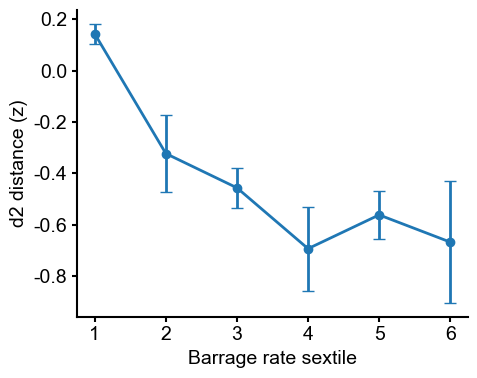

✅ Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\S3_E_pooled_D2Z_vs_barrage_tile_equalwidth.svg

Barrage: D2(z) vs tile trend
  slope     : -0.143059
  intercept : 0.0740364
  rvalue    : -0.86054
  pvalue    : 0.0278174
  stderr    : 0.0423407
  Pearson r   : -0.8605
  Pearson p   : 0.02782

✅ Done.


In [1]:
import os, glob, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

# ==========================
# ---------- STYLE ----------
# ==========================
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5
mpl.rcParams["xtick.major.width"] = 1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5


# ==========================
# ---------- I/O ----------
# ==========================
def load_pooled_per_center(save_dir, state_filter="NREM"):
    """
    Loads all *.pkl in save_dir. Each pkl is either:
      - dict with key "per_center" (DataFrame), or
      - a DataFrame directly
    """
    if not os.path.isdir(save_dir):
        raise FileNotFoundError(save_dir)
    files = sorted(glob.glob(os.path.join(save_dir, "*.pkl")))
    if not files:
        raise FileNotFoundError(f"No .pkl in {save_dir}")

    want_num = ["center_s", "d2", "n_spikes", "ripple_rate", "barrage_rate"]

    out = []
    for f in files:
        try:
            obj = pd.read_pickle(f)
        except Exception:
            with open(f, "rb") as fh:
                obj = pickle.load(fh)

        if isinstance(obj, dict):
            df = obj.get("per_center")
            if not isinstance(df, pd.DataFrame):
                continue
            animal, day = obj.get("animal_name"), obj.get("day")
        elif isinstance(obj, pd.DataFrame):
            df, animal, day = obj.copy(), None, None
        else:
            continue

        base = os.path.splitext(os.path.basename(f))[0].split("_")
        df["animal_name"] = df.get("animal_name", animal or (base[0] if base else "unknown"))
        df["day"]         = df.get("day",         day    or (base[1] if len(base) > 1 else "unknown"))

        if "state" in df.columns and state_filter is not None:
            df = df[df["state"].astype(str).str.lower() == str(state_filter).lower()]
            if df.empty:
                continue

        for c in want_num:
            if c in df.columns:
                df[c] = pd.to_numeric(df[c], errors="coerce")

        out.append(df)

    if not out:
        return pd.DataFrame()

    pooled = pd.concat(out, ignore_index=True)
    sort_cols = [c for c in ["animal_name", "day", "center_s"] if c in pooled.columns]
    return pooled.sort_values(sort_cols).reset_index(drop=True)


# ==========================
# ------ per-session z ------
# ==========================
def add_session_zscores(df, target_cols, session_cols=("animal_name", "day"), robust=False, eps=1e-12):
    """
    Adds per-session z-scores for target_cols:
      new column name: f"{col}_z"
    """
    cols = [target_cols] if isinstance(target_cols, str) else list(target_cols)
    x = df.copy()
    g = x.groupby(list(session_cols), dropna=False)

    for c in cols:
        if c not in x.columns:
            raise KeyError(f"Missing target col: {c}")

        if robust:
            med = g[c].transform("median")
            mad = g[c].transform(lambda s: np.median(np.abs(s - np.median(s))))
            z = (x[c] - med) / (1.4826 * mad + eps)
        else:
            mu = g[c].transform("mean")
            sd = g[c].transform(lambda s: s.std(ddof=1))
            z = (x[c] - mu) / sd

        z = pd.to_numeric(z, errors="coerce")
        z[~np.isfinite(z)] = np.nan
        x[f"{c}_z"] = z

    return x


# ==========================
# ------ per-session tiles ---
# ==========================
def add_session_tiles(
    df,
    by="barrage",
    k=6,
    mode="quantile",  # "quantile" (equal-count) OR "width" (equal-width)
    session_cols=("animal_name", "day"),
    middle_on_constant=True,
    eps=1e-12
):
    """
    Adds per-session tiles for rate (barrage or ripple).

    mode:
      - "quantile": equal-count bins per session (uses qcut; fallback to rank-percentiles)
      - "width":    equal-width bins per session (uses cut on [min,max])

    tile column name: tile_{by}_sess
    """
    rate = {"ripple": "ripple_rate", "barrage": "barrage_rate"}.get(str(by).lower())
    if not rate:
        raise ValueError("by must be 'ripple' or 'barrage'")

    mode = str(mode).lower()
    if mode not in ("quantile", "width"):
        raise ValueError("mode must be 'quantile' or 'width'")

    x = df.copy()
    tcol = f"tile_{by}_sess"
    x[tcol] = np.nan

    for _, sub in x.groupby(list(session_cols), dropna=False):
        r = pd.to_numeric(sub[rate], errors="coerce")
        ok = r.index[np.isfinite(r.to_numpy(float))]
        r = r.loc[ok]
        rvals = r.to_numpy(float)
        ok = ok[np.isfinite(rvals)]
        rvals = rvals[np.isfinite(rvals)]

        if rvals.size < 2:
            continue

        rmin, rmax = float(np.nanmin(rvals)), float(np.nanmax(rvals))

        # constant session
        if not np.isfinite(rmin) or not np.isfinite(rmax) or abs(rmax - rmin) < eps:
            if middle_on_constant:
                x.loc[ok, tcol] = int(np.ceil(k / 2))
            continue

        if mode == "quantile":
            # Equal-count bins
            try:
                q = pd.qcut(rvals, q=k, labels=False, duplicates="drop")
                lab = pd.Series(q.astype(int) + 1, index=ok)
                # compress to consecutive 1..U if duplicates="drop" reduced bins
                uniq = {old: i + 1 for i, old in enumerate(sorted(lab.unique()))}
                x.loc[lab.index, tcol] = lab.map(uniq).to_numpy(int)
            except Exception:
                # fallback: percentile ranks (still equal-count-ish)
                ranks = pd.Series(rvals, index=ok).rank(method="average", pct=True)
                x.loc[ok, tcol] = np.clip(np.ceil(ranks * k).astype(int), 1, k)

        else:
            # mode == "width": Equal-width bins between min and max
            # bins edges: [min, ..., max], with include_lowest=True
            try:
                b = pd.cut(
                    rvals,
                    bins=k,
                    labels=False,
                    include_lowest=True,
                    right=True
                )
                # b is 0..(k-1); make it 1..k
                lab = pd.Series(b.astype(int) + 1, index=ok)
                x.loc[lab.index, tcol] = lab.to_numpy(int)
            except Exception:
                # fallback: manual equal-width via normalized position
                frac = (rvals - rmin) / (rmax - rmin)
                x.loc[ok, tcol] = np.clip(np.floor(frac * k).astype(int) + 1, 1, k)

    return x


# ==========================
# -------- aggregate --------
# ==========================
def aggregate_from_precomputed_tiles(
    df, tile_col, value_col, rate_col,
    session_cols=("animal_name", "day"),
    equal_session_weight=True,
    error_mode="sessions"
):
    """
    Aggregates value_col within each tile:
      - equal_session_weight=True: average session means (each session counts equally)
      - error_mode: 'sessions'|'windows'|'auto'
    """
    def sem(a):
        a = pd.to_numeric(pd.Series(a), errors="coerce")
        a = a[np.isfinite(a)]
        return np.nan if a.size <= 1 else float(a.std(ddof=1) / np.sqrt(a.size))

    need = {tile_col, value_col, rate_col}
    missing = [c for c in need if c not in df.columns]
    if missing:
        raise KeyError(f"Missing {missing}")

    x = df[np.isfinite(df[value_col]) & np.isfinite(df[rate_col]) & np.isfinite(df[tile_col])].copy()
    if x.empty:
        return pd.DataFrame(columns=[tile_col, f"{value_col}_mean", f"{value_col}_sem",
                                     f"{value_col}_median", "n_sessions", "n_windows",
                                     f"{rate_col}_mean", f"{rate_col}_min", f"{rate_col}_max"])

    if equal_session_weight:
        g1 = x.groupby(list(session_cols) + [tile_col], dropna=False)
        sess_val = g1[value_col].mean().rename("v")
        sess_rt  = g1[rate_col].mean().rename("r")

        g2 = sess_val.reset_index().groupby(tile_col, dropna=False)
        out = pd.DataFrame({
            tile_col: g2.size().index,
            f"{value_col}_mean":   g2["v"].mean().to_numpy(),
            f"{value_col}_median": g2["v"].median().to_numpy(),
            "n_sessions":          g2.size().to_numpy()
        })

        out["n_windows"] = x.groupby(tile_col, dropna=False).size().reindex(out[tile_col]).to_numpy()

        sem_sessions = g2["v"].apply(sem).reindex(out[tile_col]).to_numpy()
        sem_windows  = x.groupby(tile_col, dropna=False)[value_col].apply(sem).reindex(out[tile_col]).to_numpy()

        out[f"{value_col}_sem_sessions"] = sem_sessions
        out[f"{value_col}_sem_windows"]  = sem_windows

        rt_by_tile = sess_rt.reset_index().groupby(tile_col)["r"]
        out[f"{rate_col}_mean"] = rt_by_tile.mean().reindex(out[tile_col]).to_numpy()
        out[f"{rate_col}_min"]  = rt_by_tile.min().reindex(out[tile_col]).to_numpy()
        out[f"{rate_col}_max"]  = rt_by_tile.max().reindex(out[tile_col]).to_numpy()

        if error_mode == "sessions":
            out[f"{value_col}_sem"] = out[f"{value_col}_sem_sessions"]
        elif error_mode == "windows":
            out[f"{value_col}_sem"] = out[f"{value_col}_sem_windows"]
        elif error_mode == "auto":
            y = out[f"{value_col}_sem_sessions"].to_numpy()
            y2 = out[f"{value_col}_sem_windows"].to_numpy()
            n = out["n_sessions"].to_numpy(int)
            bad = (n < 2) | (~np.isfinite(y))
            y[bad] = y2[bad]
            out[f"{value_col}_sem"] = y
        else:
            raise ValueError("error_mode ∈ {'sessions','windows','auto'}")
    else:
        g = x.groupby(tile_col, dropna=False)
        out = pd.DataFrame({
            tile_col: g.size().index,
            f"{value_col}_mean":   g[value_col].mean().to_numpy(),
            f"{value_col}_median": g[value_col].median().to_numpy(),
            "n_windows":           g.size().to_numpy(),
            f"{value_col}_sem_windows": g[value_col].apply(sem).to_numpy(),
            f"{rate_col}_mean": g[rate_col].mean().to_numpy(),
            f"{rate_col}_min":  g[rate_col].min().to_numpy(),
            f"{rate_col}_max":  g[rate_col].max().to_numpy(),
        })
        out["n_sessions"] = np.nan
        out[f"{value_col}_sem"] = out[f"{value_col}_sem_windows"]

    return out.sort_values(tile_col).reset_index(drop=True)


# ==========================
# -------- plotting ---------
# ==========================
def plot_tiles_line_barrage_only(
    tiles_barrage,
    value_col="d2_z",
    suptitle=None,
    figsize=(5, 4),
    tile_col="tile_barrage_sess"
):
    """
    Single-panel line plot: d2 (z/session) vs barrage-rate tiles.
    Uses the SEM column produced by aggregate_from_precomputed_tiles:
      f"{value_col}_sem"
    """
    def style(ax):
        ax.grid(False)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    fig, ax = plt.subplots(figsize=figsize)
    style(ax)

    mean_col = f"{value_col}_mean"
    sem_col  = f"{value_col}_sem"

    if not isinstance(tiles_barrage, pd.DataFrame) or tiles_barrage.empty:
        ax.text(0.5, 0.5, "No data", ha="center", va="center")
        return fig

    if mean_col not in tiles_barrage.columns or tile_col not in tiles_barrage.columns:
        ax.text(0.5, 0.5, f"Missing '{mean_col}' or '{tile_col}'", ha="center", va="center")
        return fig

    d = tiles_barrage.dropna(subset=[mean_col]).sort_values(tile_col)
    if d.empty:
        ax.text(0.5, 0.5, "No valid data", ha="center", va="center")
        return fig

    x = d[tile_col].to_numpy(int)
    y = d[mean_col].to_numpy(float)
    yerr = d[sem_col].to_numpy(float) if sem_col in d.columns else None

    ax.errorbar(x, y, yerr=yerr, marker="o", linewidth=2, capsize=4, color="tab:blue")
    ax.set_xticks(x)
    ax.set_xlabel("Barrage rate sextile")
    ax.set_ylabel("d2 distance (z)")

    if suptitle:
        fig.suptitle(suptitle, y=1.02)

    fig.tight_layout()
    return fig


# ==========================
# ----- trend helpers -------
# ==========================
def compute_linear_trend(x, y, use_scipy=True):
    """
    Compute linear trend y = slope*x + intercept.

    Returns dict with:
      slope, intercept, rvalue, pvalue, stderr
    """
    from scipy.stats import linregress
    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 2:
        return dict(slope=np.nan, intercept=np.nan,
                    rvalue=np.nan, pvalue=np.nan, stderr=np.nan)

    if use_scipy:
        res = linregress(x[mask], y[mask])
        return dict(slope=float(res.slope), intercept=float(res.intercept),
                    rvalue=float(res.rvalue), pvalue=float(res.pvalue), stderr=float(res.stderr))

    A = np.vstack([x[mask], np.ones(mask.sum())]).T
    slope, intercept = np.linalg.lstsq(A, y[mask], rcond=None)[0]
    yhat = slope * x[mask] + intercept
    ss_res = np.sum((y[mask] - yhat) ** 2)
    ss_tot = np.sum((y[mask] - y[mask].mean()) ** 2)
    r = np.sqrt(max(0, 1 - ss_res / ss_tot)) if ss_tot > 0 else np.nan
    return dict(slope=float(slope), intercept=float(intercept),
                rvalue=float(r), pvalue=np.nan, stderr=np.nan)


def safe_pearsonr(x, y):
    from scipy.stats import pearsonr
    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 2:
        return np.nan, np.nan
    r, p = pearsonr(x[mask], y[mask])
    return float(r), float(p)


# ==========================
# ---------- pipeline -------
# ==========================
if __name__ == "__main__":
    save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\barr_ablate"
    save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp"

    # Choose tile mode:
    #   "quantile" -> sextiles/equal-count (pd.qcut)
    #   "width"    -> equal-width bins (pd.cut)
    TILE_MODE = "width"  # change to "width" for equal-width tiles
    K_TILES = 6

    pooled_df = load_pooled_per_center(save_dir, state_filter="NREM")
    if pooled_df.empty:
        raise RuntimeError("No pooled data found.")

    if "d2" not in pooled_df.columns:
        raise KeyError("Your pooled_df has no 'd2' column. Check your per_center outputs.")
    if "barrage_rate" not in pooled_df.columns:
        raise KeyError("Your pooled_df has no 'barrage_rate' column. Check your per_center outputs.")

    # Tiles: barrage only, per-session
    pooled_df = add_session_tiles(pooled_df, by="barrage", k=K_TILES, mode=TILE_MODE)

    # Z-score d2 within (animal_name, day)
    pooled_df = add_session_zscores(pooled_df, "d2", robust=False)

    # Aggregate d2_z vs barrage tiles
    tiles_bar = aggregate_from_precomputed_tiles(
        pooled_df,
        tile_col="tile_barrage_sess",
        value_col="d2_z",
        rate_col="barrage_rate",
        equal_session_weight=True,
        error_mode="sessions"   # cross-session SEM (SEM of session means)
    )

    # Plot
    fig_bar = plot_tiles_line_barrage_only(
        tiles_bar,
        value_col="d2_z",
        suptitle=None,
        tile_col="tile_barrage_sess"
    )
    plt.show()

    # Save
    os.makedirs(save_path, exist_ok=True)
    tag = "sextile" if TILE_MODE == "quantile" else "equalwidth"
    out_plot = os.path.join(save_path, f"S3_E_pooled_D2Z_vs_barrage_tile_{tag}.svg")
    fig_bar.savefig(out_plot, dpi=300, bbox_inches="tight")
    print("✅ Saved:", out_plot)

    # Trends (on tile means)
    trend_bar = compute_linear_trend(
        tiles_bar["tile_barrage_sess"],
        tiles_bar["d2_z_mean"]
    )
    r_bar, p_bar = safe_pearsonr(
        tiles_bar["tile_barrage_sess"],
        tiles_bar["d2_z_mean"]
    )

    print("\nBarrage: D2(z) vs tile trend")
    for k, v in trend_bar.items():
        print(f"  {k:10s}: {v:.6g}")
    print(f"  Pearson r   : {r_bar:.4f}")
    print(f"  Pearson p   : {p_bar:.4g}")

    print("\n✅ Done.")